# 01 - Data check

Stage 1 of the project: confirm the data is complete and sensible before any modelling.
Runs top to bottom in a fresh kernel. If the processed panels do not exist yet, it builds
them by calling the pipeline in `src/`.

In [1]:
import sys
from pathlib import Path

here = Path.cwd()
candidates = [here, *here.parents, *(d for d in here.iterdir() if d.is_dir())]
ROOT = next(p for p in candidates if (p / "src" / "config.py").exists())

sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from config import PROCESSED_DIR, RAW_DIR
import download_data, clean_data, make_figures

if not (RAW_DIR / "SPX.csv").exists():
    download_data.main()
if not (PROCESSED_DIR / "panel_spx.csv").exists():
    clean_data.main()

## 1. The two panels

In [2]:
spx = pd.read_csv(PROCESSED_DIR / "panel_spx.csv", index_col="date", parse_dates=True)
smi = pd.read_csv(PROCESSED_DIR / "panel_smi.csv", index_col="date", parse_dates=True)
print(f"S&P 500 panel: {spx.index.min().date()} -> {spx.index.max().date()}, {len(spx)} trading days")
print(f"SMI panel:     {smi.index.min().date()} -> {smi.index.max().date()}, {len(smi)} trading days")
spx.tail()

S&P 500 panel: 1990-01-02 -> 2026-10-22, 9270 trading days
SMI panel:     1990-11-09 -> 2026-10-22, 9028 trading days


,price,VIX,VIX3M,SKEW,USD_3M,USD_1Y,ret_log,rv_21d,tr_index,div_yield_raw,div_yield,vrp
date,,,,,,,,,,,,
2026-10-16,7659.439941,19.99,20.50,168.59,4.070,NaN,-1.098724,10.203885,17186.019531,1.160224,1.168021,9.786115
2026-10-19,7690.729980,18.44,19.60,161.86,4.075,NaN,0.407684,10.283318,17256.240234,1.160029,1.167754,8.156682
2026-10-20,7712.569824,17.31,18.99,160.40,4.080,NaN,0.283574,8.887672,17305.410156,1.158981,1.167558,8.422328
2026-10-21,7757.169922,16.68,18.72,150.36,4.063,NaN,0.576612,9.134917,17405.679688,1.158838,1.166876,7.545083
2026-10-22,7663.430176,19.03,20.12,152.39,4.022,NaN,-1.215788,9.729269,17195.570312,1.159805,1.166807,9.300731


## 2. Missing values per column

Expected gaps: VIX3M starts in December 2007; realised volatility needs 21 days and the
dividend yield 252 days before their first value. Anything else must be explained.

In [3]:
cols = spx.dropna(axis=1, how="all")
print("not downloaded:", [c for c in spx.columns if c not in cols.columns])
pd.DataFrame({
    "first": cols.apply(lambda c: c.first_valid_index().date()),
    "missing after first value": cols.apply(lambda c: int(c.loc[c.first_valid_index():].isna().sum())),
})


not downloaded: ['USD_1Y']


,first,missing after first value
price,1990-01-02,0
VIX,1990-01-02,0
VIX3M,2009-09-18,0
SKEW,1990-01-02,3
USD_3M,1990-01-02,0
ret_log,1990-01-03,0
rv_21d,1990-01-31,0
tr_index,1990-01-02,0
div_yield_raw,1990-12-31,0
div_yield,1991-01-29,0


## 3. Sanity checks (each line should print True)

In [4]:
checks = {
    "prices strictly positive": (spx["price"] > 0).all() and (smi["price"] > 0).all(),
    "VIX between 5 and 100": spx["VIX"].dropna().between(5, 100).all(),
    "S&P dividend yield between 0 and 5 %": spx["div_yield"].dropna().between(0, 5).all(),
    "dates strictly increasing": spx.index.is_monotonic_increasing and smi.index.is_monotonic_increasing,
}
for name, ok in checks.items():
    print(f"{str(bool(ok)):>5}  {name}")

 True  prices strictly positive
 True  VIX between 5 and 100
 True  S&P dividend yield between 0 and 5 %
 True  dates strictly increasing


## 4. How often did a one-year product knock in?

For every trading day, take the next 252 trading days of the real index path and check
whether the closing price ever fell to the barrier. This describes the data the hedging
study runs on: products issued every day, with real knock-in events to learn from.

In [5]:
def knock_in_share(price: pd.Series, barrier: float, horizon: int = 252) -> tuple[float, int]:
    p = price.dropna().to_numpy()
    n = len(p) - horizon
    # minimum of the next `horizon` closes, relative to the issue-day close
    future_min = np.array([p[i + 1:i + 1 + horizon].min() for i in range(n)]) / p[:n]
    return 100 * (future_min <= barrier).mean(), n

rows = []
for label, price in [("S&P 500", spx["price"]), ("SMI", smi["price"])]:
    for barrier in (0.6, 0.7, 0.8):
        share, n = knock_in_share(price, barrier)
        rows.append({"index": label, "barrier": f"{barrier:.0%}", "products": n,
                     "knocked in, %": round(share, 1)})
pd.DataFrame(rows)

,index,barrier,products,"knocked in, %"
0,S&P 500,60%,9018,2.7
1,S&P 500,70%,9018,5.2
2,S&P 500,80%,9018,13.5
3,SMI,60%,8776,2.0
4,SMI,70%,8776,8.1
5,SMI,80%,8776,18.7


## 5. Figures (saved to `figures/`)

Figures saved in /files/brc-deep-hedging/figures


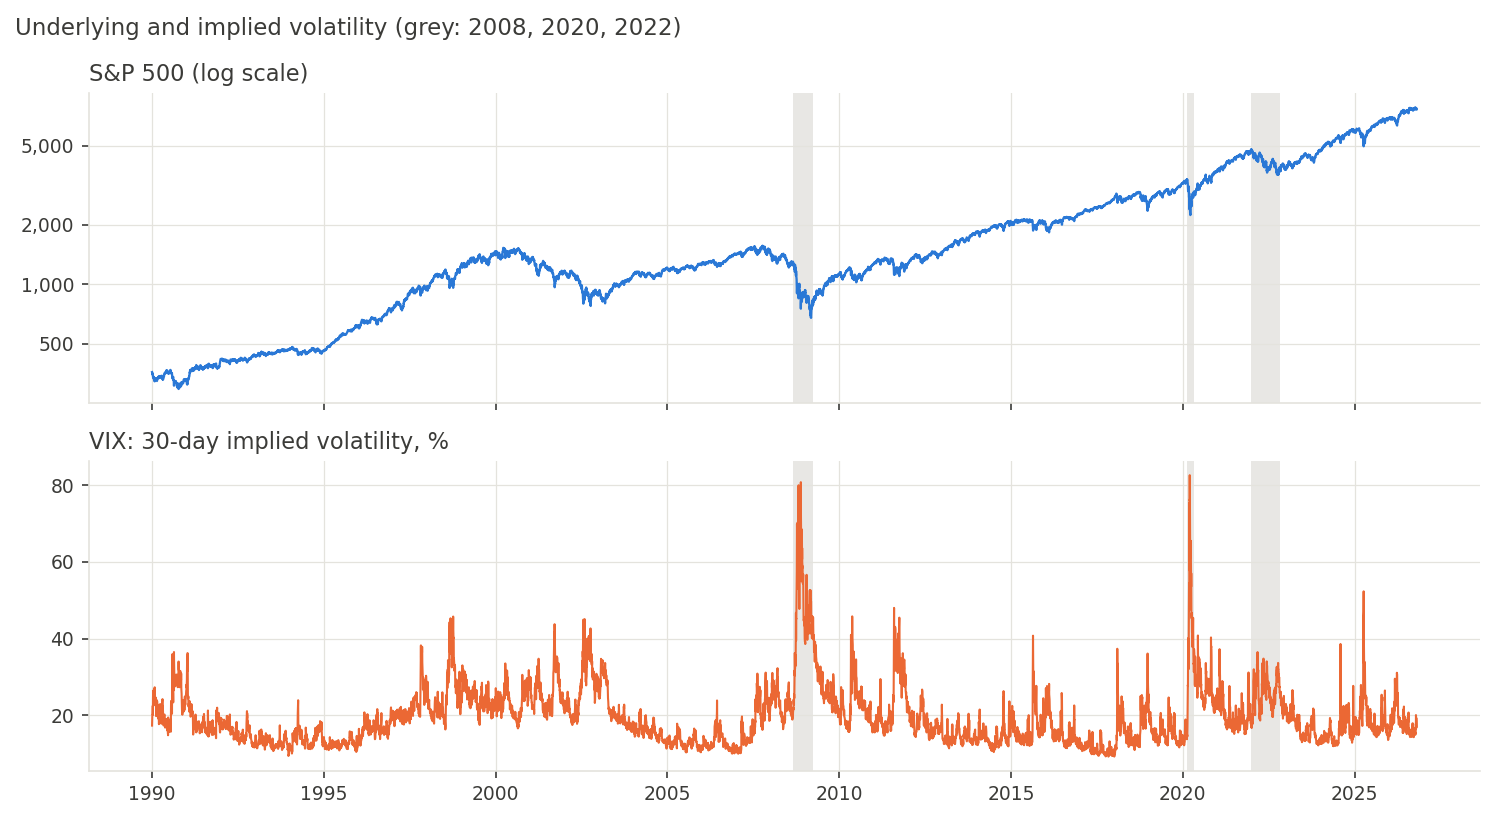

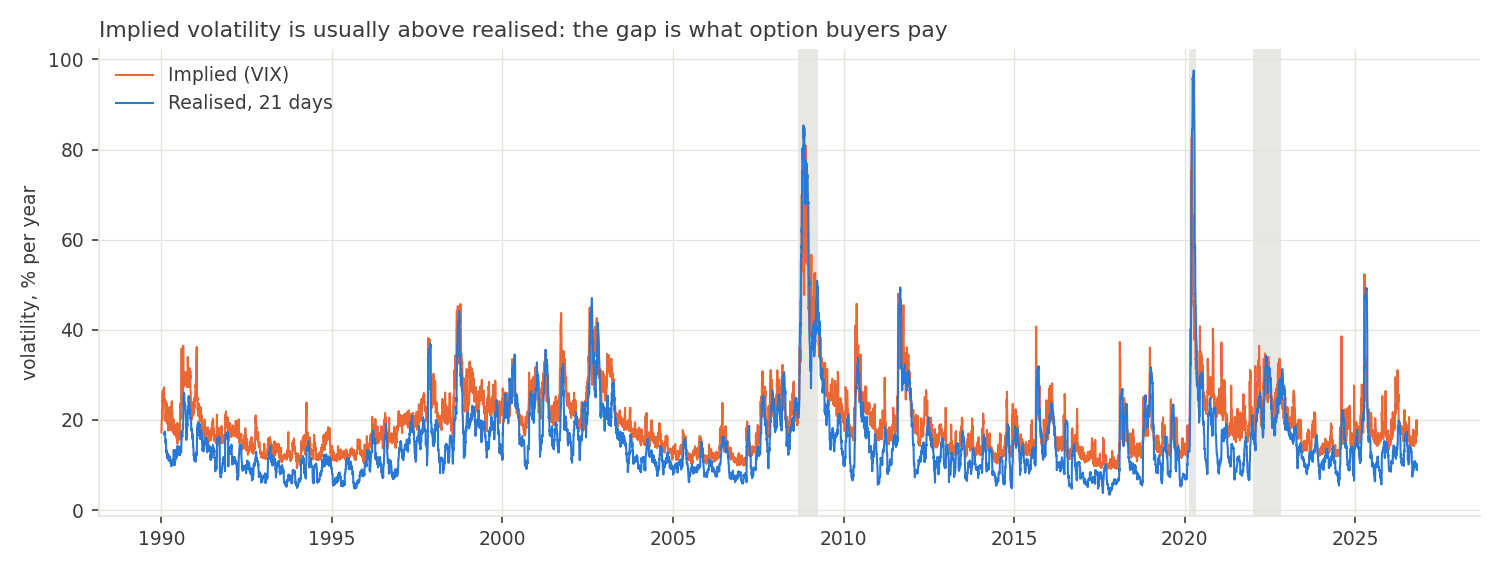

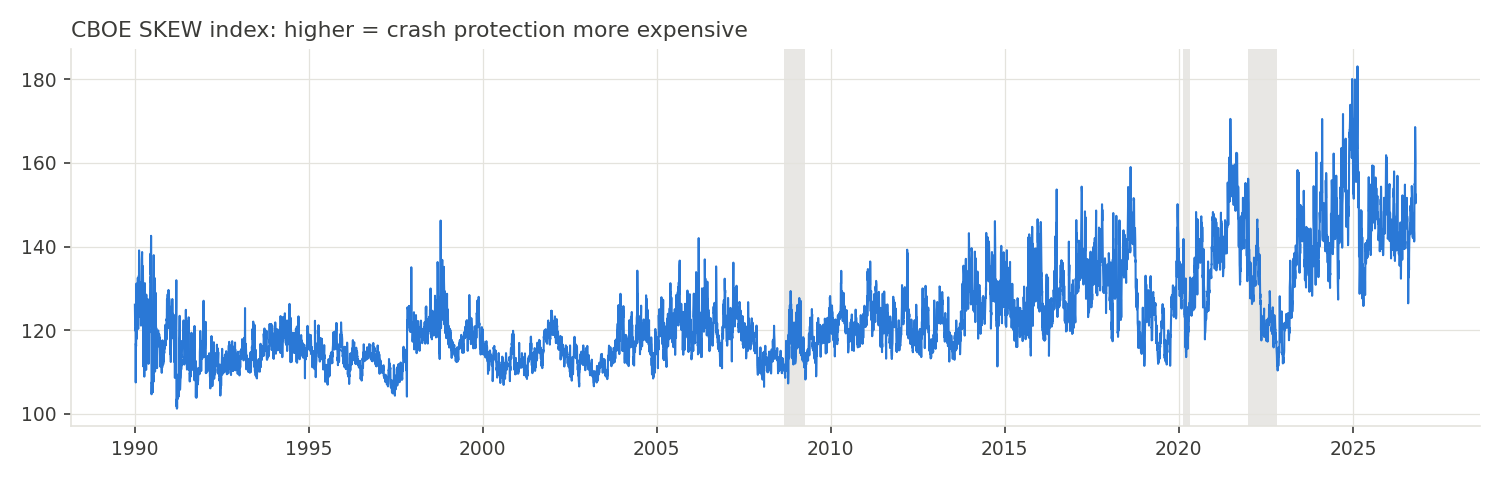

In [6]:
make_figures.main()
from IPython.display import Image, display
for f in sorted((ROOT / "figures").glob("*.png")):
    display(Image(filename=str(f)))

In [7]:
d = spx["div_yield"].dropna()
print(d.describe())
print("below 0:", (d < 0).sum(), "  above 5:", (d > 5).sum())
d[(d < 0) | (d > 5)]


count    8998.000000
mean        1.994505
std         0.530038
min         1.137443
25%         1.634926
50%         1.970837
75%         2.199369
max         3.639546
Name: div_yield, dtype: float64
below 0: 0   above 5: 0


Series([], Name: div_yield, dtype: float64)